# Orchestrateur SAV : LangGraph + MCP

### 1) Imports

In [1]:
from datetime import date
from typing import Annotated
from typing_extensions import TypedDict, Literal

from dotenv import load_dotenv
from IPython.display import Image, Markdown
from langgraph.graph import StateGraph, START, END
from langgraph.graph.message import add_messages
from langchain.agents import create_agent
from langchain.messages import HumanMessage, AIMessage, SystemMessage
from langchain.tools import tool
from langchain_google_genai import ChatGoogleGenerativeAI
from langchain_mcp_adapters.client import MultiServerMCPClient

load_dotenv(override=True)

True

### 2) État partagé

In [2]:
class SAVState(TypedDict, total=False):
    messages: Annotated[list, add_messages]
    image_ref: str
    categorie: Literal["documentation", "garantie"]
    next: Literal["agent_documentaire", "agent_garantie", "FINISH"]
    reponse_finale: str

### 3) LLM et routeur à sortie structurée

In [3]:
class Router(TypedDict):
    categorie: Literal["documentation", "garantie"]


llm = ChatGoogleGenerativeAI(model="gemini-3.5-flash-lite", temperature=0)
router_llm = llm.with_structured_output(Router)

### 4) Outil local : consulter_garantie (registre en lecture seule)

In [4]:
REGISTRE = {
    "PX200-0042": {"produit": "Imprimante PX-200", "achat": "2025-03-15", "duree_mois": 24, "fin": "2027-03-15"},
    "PX200-0007": {"produit": "Imprimante PX-200", "achat": "2022-01-10", "duree_mois": 24, "fin": "2024-01-10"},
}


@tool
def consulter_garantie(numero_serie: str) -> dict:
    """Consulte le registre (lecture seule) et retourne l'état de garantie d'un numéro de série"""
    fiche = REGISTRE.get(numero_serie.strip().upper())
    if fiche is None:
        return {"numero_serie": numero_serie, "statut": "inconnu"}
    sous_garantie = date.fromisoformat(fiche["fin"]) >= date.today()
    return {"numero_serie": numero_serie, **fiche,
            "statut": "sous garantie" if sous_garantie else "garantie expirée"}

In [5]:
print(consulter_garantie.invoke({"numero_serie": "PX200-0042"}))
print(consulter_garantie.invoke({"numero_serie": "PX200-0007"}))
print(consulter_garantie.invoke({"numero_serie": "XXXX"}))

{'numero_serie': 'PX200-0042', 'produit': 'Imprimante PX-200', 'achat': '2025-03-15', 'duree_mois': 24, 'fin': '2027-03-15', 'statut': 'sous garantie'}
{'numero_serie': 'PX200-0007', 'produit': 'Imprimante PX-200', 'achat': '2022-01-10', 'duree_mois': 24, 'fin': '2024-01-10', 'statut': 'garantie expirée'}
{'numero_serie': 'XXXX', 'statut': 'inconnu'}


### 5) Client MCP : récupérer l'outil distant rag_multimodal

In [6]:
mcp_client = MultiServerMCPClient({
    "mcp-server-sav": {
        "transport": "streamable_http",
        "url": "http://localhost:24000/mcp",
    }
})

In [7]:
mcp_tools = await mcp_client.get_tools()
mcp_tools

[StructuredTool(name='rag_multimodal', description="Répond à une question de dépannage à partir des manuels (texte + figures).\n    image_ref : référence optionnelle d'une photo de l'écran de l'appareil (ex: img_px200_01)", args_schema={'properties': {'question': {'title': 'Question', 'type': 'string'}, 'image_ref': {'default': '', 'title': 'Image Ref', 'type': 'string'}}, 'required': ['question'], 'title': 'rag_multimodalArguments', 'type': 'object'}, handle_tool_error=<function _handle_mcp_tool_error at 0x00000270CBB62DE0>, response_format='content_and_artifact', coroutine=<function convert_mcp_tool_to_langchain_tool.<locals>.call_tool at 0x00000270CCD8F420>)]

### 6) Les deux agents spécialisés

In [8]:
agent_doc = create_agent(
    model=llm, tools=mcp_tools,
    system_prompt="""Tu es l'agent documentaire du SAV.
Pour toute question de dépannage, appelle l'outil rag_multimodal en lui passant la question
et, s'il y en a une, la référence de la photo (image_ref). Réponds avec les sources.""",
)

agent_garantie = create_agent(
    model=llm, tools=[consulter_garantie],
    system_prompt="""Tu es l'agent garantie du SAV.
Extrais le numéro de série, appelle consulter_garantie et indique clairement si
l'appareil est sous garantie, avec la date de fin.""",
)

### 7) Nœuds du graphe

In [9]:
def supervisor_node(state: SAVState):
    # Une réponse finale existe -> l'orchestrateur termine
    if state.get("reponse_finale"):
        return {"next": "FINISH"}
    decision = router_llm.invoke([
        SystemMessage(content=(
            "Tu es l'orchestrateur du SAV. Classe la demande dans UNE seule catégorie :\n"
            "- documentation : dépannage, voyant, pictogramme, erreur, mode d'emploi\n"
            "- garantie : vérification de garantie à partir d'un numéro de série"
        )),
        *state["messages"],
    ])
    agent = "agent_documentaire" if decision["categorie"] == "documentation" else "agent_garantie"
    return {"categorie": decision["categorie"], "next": agent}


async def agent_documentaire_node(state: SAVState):
    question = state["messages"][-1].content
    if state.get("image_ref"):
        question += f"\n(Photo jointe, image_ref={state['image_ref']})"
    resp = await agent_doc.ainvoke({"messages": [HumanMessage(question)]})
    texte = resp["messages"][-1].text
    return {"messages": [AIMessage(content=texte, name="agent_documentaire")],
            "reponse_finale": texte}


async def agent_garantie_node(state: SAVState):
    resp = await agent_garantie.ainvoke({"messages": [HumanMessage(state["messages"][-1].content)]})
    texte = resp["messages"][-1].text
    return {"messages": [AIMessage(content=texte, name="agent_garantie")],
            "reponse_finale": texte}


def route_after_supervisor(state: SAVState):
    return state["next"]

### 8) Construction du graphe : chaque agent rend la main à l'orchestrateur

In [10]:
builder = StateGraph(SAVState)
builder.add_node("supervisor", supervisor_node)
builder.add_node("agent_documentaire", agent_documentaire_node)
builder.add_node("agent_garantie", agent_garantie_node)

builder.add_edge(START, "supervisor")
builder.add_conditional_edges("supervisor", route_after_supervisor, {
    "agent_documentaire": "agent_documentaire",
    "agent_garantie": "agent_garantie",
    "FINISH": END,
})
builder.add_edge("agent_documentaire", "supervisor")   # l'agent rend la main
builder.add_edge("agent_garantie", "supervisor")
graph = builder.compile()

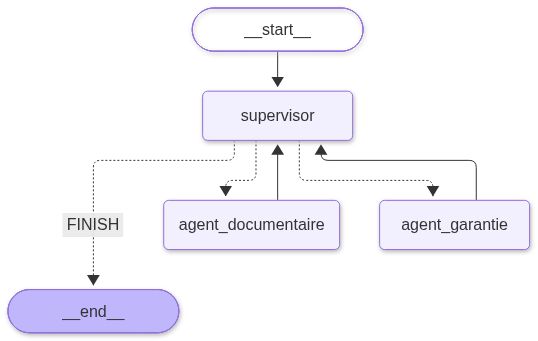

In [11]:
display(Image(graph.get_graph().draw_mermaid_png()))

### 9) Exemple 1 : assistance documentaire

In [12]:
r1 = await graph.ainvoke({
    "messages": [HumanMessage("Mon imprimante PX-200 affiche un voyant clignotant. "
                              "Que signifie le pictogramme sur la photo jointe ?")],
    "image_ref": "img_px200_01",
})
print("Catégorie :", r1["categorie"], "| Agent :", r1["messages"][-1].name)
display(Markdown(r1["reponse_finale"]))

c:\Users\dell\Desktop\TP5-Agentic AI_MCP\.venv\Lib\site-packages\langchain_google_genai\chat_models.py:3982: UserWarning: Model 'gemini-3.5-flash-lite' uses fixed sampling defaults; the sampling parameter(s) temperature will be ignored.
  request = self._build_request_config(


Catégorie : documentation | Agent : agent_documentaire


Le pictogramme de la feuille froissée affiché à l'écran et le voyant orange clignotant indiquent un **bourrage papier** (Manuel PX-200, page 3, Figure 3.1 et page 4, Figure 4.1).

**Procédure pour résoudre le problème :**
1. Éteignez l'imprimante (Manuel PX-200, page 4).
2. Ouvrez le capot arrière (Manuel PX-200, page 4).
3. Retirez délicatement la feuille coincée, sans la déchirer (Manuel PX-200, page 4).
4. Refermez le capot, rallumez l'imprimante et relancez l'impression (Manuel PX-200, page 4).

### 10) Exemple 2 : vérification de garantie

In [13]:
r2 = await graph.ainvoke({
    "messages": [HumanMessage("Est-ce que mon imprimante est encore sous garantie ? "
                              "Son numéro de série est PX200-0042.")]
})
print("Catégorie :", r2["categorie"], "| Agent :", r2["messages"][-1].name)
display(Markdown(r2["reponse_finale"]))

Catégorie : garantie | Agent : agent_garantie


Votre imprimante (numéro de série : PX200-0042) est actuellement **sous garantie**. 

La garantie court jusqu'au **15 mars 2027**.

### 11) Trace complète (pour le rapport)

In [14]:
for m in r1["messages"]:
    m.pretty_print()

================================ Human Message =================================

Mon imprimante PX-200 affiche un voyant clignotant. Que signifie le pictogramme sur la photo jointe ?
================================== Ai Message ==================================
Name: agent_documentaire

Le pictogramme de la feuille froissée affiché à l'écran et le voyant orange clignotant indiquent un **bourrage papier** (Manuel PX-200, page 3, Figure 3.1 et page 4, Figure 4.1).

**Procédure pour résoudre le problème :**
1. Éteignez l'imprimante (Manuel PX-200, page 4).
2. Ouvrez le capot arrière (Manuel PX-200, page 4).
3. Retirez délicatement la feuille coincée, sans la déchirer (Manuel PX-200, page 4).
4. Refermez le capot, rallumez l'imprimante et relancez l'impression (Manuel PX-200, page 4).
